In [1]:
import os
import numpy as np
from PIL import Image

DATA_DIR = "data-rescaled"
IMG_SIZE = 64

# each folder name is one class (e.g. 10_front, 500_back)
class_names = sorted([d for d in os.listdir(DATA_DIR)
                      if os.path.isdir(os.path.join(DATA_DIR, d)) and not d.startswith(".")])
num_classes = len(class_names)
print("Classes:", class_names)

images, labels = [], []
for label, name in enumerate(class_names):
    folder = os.path.join(DATA_DIR, name)
    for file in os.listdir(folder):
        if file.lower().endswith(".jpg"):
            img = Image.open(os.path.join(folder, file)).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            images.append(np.array(img))
            labels.append(label)

X = np.array(images)
y = np.array(labels)
print("Images:", X.shape, "Labels:", y.shape)

Classes: ['1000_back', '1000_front', '100_back', '100_front', '10_back', '10_front', '20_back', '20_front', '5000_back', '5000_front', '500_back', '500_front', '50_back', '50_front']
Images: (3611, 64, 64, 3) Labels: (3611,)


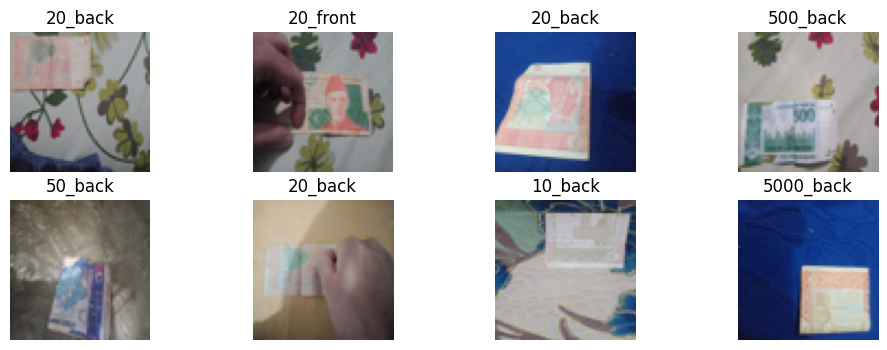

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
for i in range(8):
    idx = np.random.randint(len(X))
    plt.subplot(2, 4, i + 1)
    plt.imshow(X[idx])
    plt.title(class_names[y[idx]])
    plt.axis("off")
plt.show()

In [3]:
from sklearn.model_selection import train_test_split

X = X.astype("float32") / 255.0      # normalize pixels from 0-255 to 0-1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (2888, 64, 64, 3) | Test: (723, 64, 64, 3)


In [4]:
import tensorflow as tf
from tensorflow.keras import layers

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)   # avoids overfitting

mlp = tf.keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),                                          # avoids overfitting
    layers.Dense(128, activation="relu"),
    layers.Dense(num_classes, activation="softmax"),
])

mlp.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

mlp_history = mlp.fit(X_train, y_train, validation_split=0.1,
                      epochs=30, batch_size=32, callbacks=[early_stop])

mlp_loss, mlp_acc = mlp.evaluate(X_test, y_test)
print("MLP Test Accuracy:", mlp_acc)

Epoch 1/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.0658 - loss: 3.1706 - val_accuracy: 0.0761 - val_loss: 2.6388
Epoch 2/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.0781 - loss: 2.6390 - val_accuracy: 0.0761 - val_loss: 2.6389
Epoch 3/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.0785 - loss: 2.6385 - val_accuracy: 0.0761 - val_loss: 2.6392
Epoch 4/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.0770 - loss: 2.6405 - val_accuracy: 0.0761 - val_loss: 2.6395
Epoch 5/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.0781 - loss: 2.6381 - val_accuracy: 0.0761 - val_loss: 2.6398
Epoch 6/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.0781 - loss: 2.6378 - val_accuracy: 0.0761 - val_loss: 2.6402
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0775 - loss: 2.6390
MLP Test Accuracy: 0.0774550512433052


In [5]:
cnn = tf.keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation="softmax"),
])

cnn.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

cnn_history = cnn.fit(X_train, y_train, validation_split=0.1,
                      epochs=30, batch_size=32, callbacks=[early_stop])

cnn_loss, cnn_acc = cnn.evaluate(X_test, y_test)
print("CNN Test Accuracy:", cnn_acc)

Epoch 1/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 10s 79ms/step - accuracy: 0.0858 - loss: 2.6379 - val_accuracy: 0.1246 - val_loss: 2.6186
Epoch 2/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 72ms/step - accuracy: 0.1174 - loss: 2.5617 - val_accuracy: 0.1765 - val_loss: 2.4910
Epoch 3/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - accuracy: 0.1431 - loss: 2.4621 - val_accuracy: 0.1384 - val_loss: 2.4281
Epoch 4/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.1693 - loss: 2.3672 - val_accuracy: 0.2145 - val_loss: 2.2723
Epoch 5/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.2043 - loss: 2.2327 - val_accuracy: 0.2768 - val_loss: 2.1129
Epoch 6/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - accuracy: 0.2636 - loss: 2.0972 - val_accuracy: 0.3010 - val_loss: 1.9985
Epoch 7/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.2859 - loss: 1.9894 - val_accuracy: 0.4014 - val_loss: 1.7216
Epoch 8/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.3440 - loss: 1.8080 - val_accuracy: 0.4083 - 

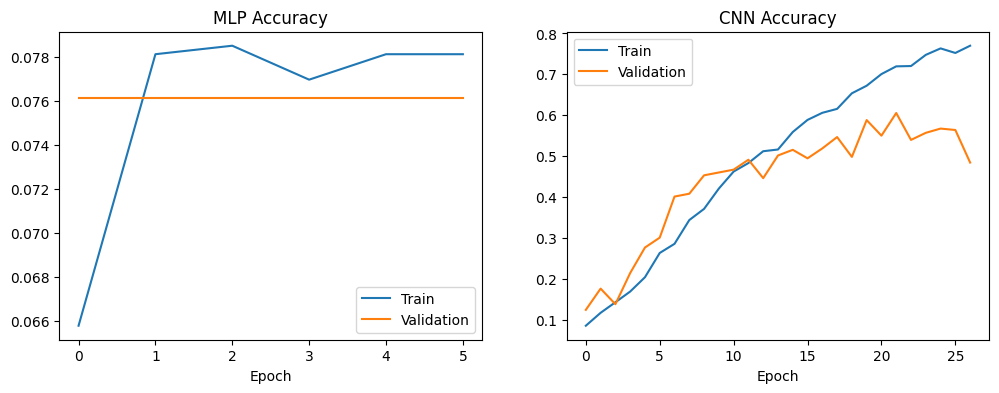

MLP Test Accuracy: 0.0775
CNN Test Accuracy: 0.5947


In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(mlp_history.history["accuracy"], label="Train")
plt.plot(mlp_history.history["val_accuracy"], label="Validation")
plt.title("MLP Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["accuracy"], label="Train")
plt.plot(cnn_history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.show()

print(f"MLP Test Accuracy: {mlp_acc:.4f}")
print(f"CNN Test Accuracy: {cnn_acc:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step
              precision    recall  f1-score   support

   1000_back       0.43      0.55      0.48        47
  1000_front       0.45      0.42      0.44        45
    100_back       0.68      0.71      0.70        56
   100_front       0.70      0.70      0.70        56
     10_back       0.53      0.50      0.51        56
    10_front       0.49      0.67      0.57        54
     20_back       0.63      0.50      0.56        52
    20_front       0.88      0.72      0.79        50
   5000_back       0.66      0.48      0.56        52
  5000_front       0.59      0.69      0.64        51
    500_back       0.56      0.62      0.59        52
   500_front       0.45      0.43      0.44        53
     50_back       0.72      0.76      0.74        51
    50_front       0.68      0.54      0.60        48

    accuracy                           0.59       723
   macro avg       0.60      0.59      0.59       723
weighted avg       0.61      0.59      0

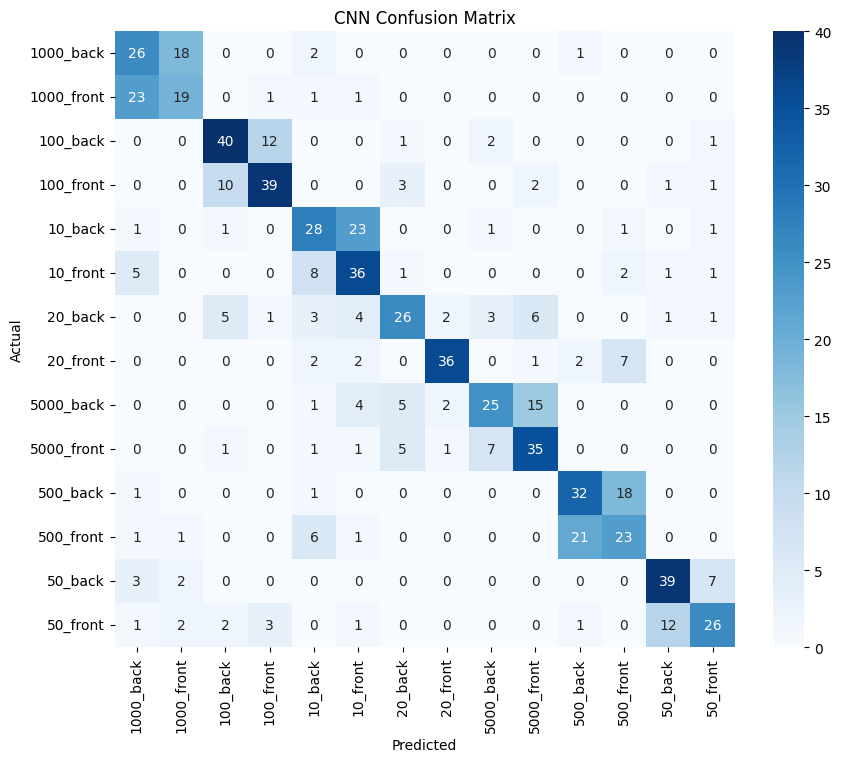

In [7]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_pred = np.argmax(cnn.predict(X_test), axis=1)

print(classification_report(y_test, y_pred, target_names=class_names))

plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")
plt.show()

In [8]:
import gradio as gr

def predict_note(image):
    img = image.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    arr = np.array(img, dtype="float32") / 255.0
    arr = np.expand_dims(arr, axis=0)
    probs = cnn.predict(arr, verbose=0)[0]
    return {class_names[i]: float(probs[i]) for i in range(num_classes)}

demo = gr.Interface(
    fn=predict_note,
    inputs=gr.Image(type="pil", label="Upload a Pakistani currency note"),
    outputs=gr.Label(num_top_classes=3, label="Prediction"),
    title="Pakistani Currency Note Recognition",
)
demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [9]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

print("Total images:", len(X), "| Classes:", num_classes)
print("Train:", len(X_train), "| Test:", len(X_test))
print("MLP parameters:", mlp.count_params(), "| CNN parameters:", cnn.count_params())
print("MLP epochs run:", len(mlp_history.history["loss"]))
print("CNN epochs run:", len(cnn_history.history["loss"]))

for name, model, hist in [("MLP", mlp, mlp_history), ("CNN", cnn, cnn_history)]:
    y_hat = np.argmax(model.predict(X_test, verbose=0), axis=1)
    p, r, f, _ = precision_recall_fscore_support(y_test, y_hat, average="weighted", zero_division=0)
    print(f"\n{name}: test acc={accuracy_score(y_test, y_hat):.4f}, precision={p:.4f}, recall={r:.4f}, F1={f:.4f}")
    print(f"{name}: last train acc={hist.history['accuracy'][-1]:.4f}, last val acc={hist.history['val_accuracy'][-1]:.4f}")

Total images: 3611 | Classes: 14
Train: 2888 | Test: 723
MLP parameters: 3180686 | CNN parameters: 685006
MLP epochs run: 6
CNN epochs run: 27

MLP: test acc=0.0775, precision=0.0060, recall=0.0775, F1=0.0111
MLP: last train acc=0.0781, last val acc=0.0761

CNN: test acc=0.5947, precision=0.6054, recall=0.5947, F1=0.5954
CNN: last train acc=0.7699, last val acc=0.4844


In [ ]:
cnn.summary()

In [10]:
import json

cnn.save("currency_cnn.keras")
with open("class_names.json", "w") as f:
    json.dump(class_names, f)
print("Saved")

Saved


In [11]:
import io
import base64
import threading
import numpy as np
from PIL import Image
from flask import Flask, render_template_string, request
from werkzeug.serving import make_server

# stop the old server if you run this cell again
try:
    server.shutdown()
except NameError:
    pass

app = Flask(__name__)

page = """
<!DOCTYPE html>
<html>
<head>
    <title>Pakistani Currency Note Recognition</title>
    <style>
        body { font-family: Arial; background: #f2f5f3; padding: 30px; }
        .box { max-width: 520px; margin: auto; background: white; padding: 28px;
               border-radius: 10px; box-shadow: 0 2px 8px rgba(0,0,0,0.15); text-align: center; }
        h1 { font-size: 22px; color: #1b5e20; }
        button { background: #1b5e20; color: white; border: none; padding: 10px 24px;
                 font-size: 15px; border-radius: 6px; cursor: pointer; }
        img { max-width: 100%; margin-top: 20px; border-radius: 6px; }
        .row { text-align: left; margin-top: 12px; }
        .bar { background: #e0e0e0; border-radius: 5px; height: 16px; }
        .fill { background: #2e7d32; height: 16px; border-radius: 5px; }
    </style>
</head>
<body>
    <div class="box">
        <h1>Pakistani Currency Note Recognition</h1>
        <p>Upload an image of a note.</p>
        <form method="POST" enctype="multipart/form-data">
            <input type="file" name="image" accept="image/*"><br><br>
            <button type="submit">Predict</button>
        </form>
        {% if error %}<p style="color:red">{{ error }}</p>{% endif %}
        {% if preview %}<img src="data:image/jpeg;base64,{{ preview }}">{% endif %}
        {% if results %}
            <h3>Top 3 Predictions</h3>
            {% for name, score in results %}
            <div class="row">
                <b>{{ name }}</b> - {{ score }}%
                <div class="bar"><div class="fill" style="width: {{ score }}%"></div></div>
            </div>
            {% endfor %}
        {% endif %}
    </div>
</body>
</html>
"""

@app.route("/", methods=["GET", "POST"])
def home():
    results, preview, error = None, None, None
    if request.method == "POST":
        file = request.files.get("image")
        if file is None or file.filename == "":
            error = "Please choose an image first."
        else:
            try:
                img = Image.open(file.stream).convert("RGB")

                small = img.copy()
                small.thumbnail((350, 350))
                buffer = io.BytesIO()
                small.save(buffer, format="JPEG")
                preview = base64.b64encode(buffer.getvalue()).decode("utf-8")

                arr = np.array(img.resize((IMG_SIZE, IMG_SIZE)), dtype="float32") / 255.0
                arr = np.expand_dims(arr, axis=0)

                probs = cnn.predict(arr, verbose=0)[0]
                top3 = np.argsort(probs)[::-1][:3]
                results = [(class_names[i], round(float(probs[i]) * 100, 2)) for i in top3]
            except Exception:
                error = "This is not a valid image. Please upload a JPG or PNG."
    return render_template_string(page, results=results, preview=preview, error=error)

server = make_server("127.0.0.1", 5000, app)
threading.Thread(target=server.serve_forever, daemon=True).start()
print("Flask is running. Open this link in your browser: http://127.0.0.1:5000")

Flask is running. Open this link in your browser: http://127.0.0.1:5000
